# 01 · Entendimiento y calidad de los datos — Inasistencia a citas (no-show)
**MINE-4101 Ciencia de Datos Aplicada · Proyecto final · Entrega 1**

Objetivo: describir la estructura, calidad y suficiencia del conjunto *Medical Appointment No Shows*
(citas ambulatorias del sistema público de Vitória, ES, Brasil; abril–junio 2016) como **conjunto proxy**
para validar el enfoque analítico antes de recibir datos de MinHalma (organización aliada).

Orden de ejecución: este notebook es autocontenido; ejecutar de arriba a abajo. Semilla fija = 42.

In [1]:
import json
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))
from utils import (cramers_v, logit_or_table, mann_whitney_rb, mantel_haenszel_or,
                   rate_table, wilson_ci)

SEED = 42
RAW = ROOT / "data" / "raw" / "KaggleV2-May-2016.csv"
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
TAB = ROOT / "reports" / "tables"; TAB.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook", font="DejaVu Sans")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight"})
pd.set_option("display.width", 140, "display.max_columns", 30)
RESULTS = {}  # métricas clave que alimentan el reporte ejecutivo

## 1. Carga y estructura

In [2]:
raw = pd.read_csv(RAW)
print("Dimensiones:", raw.shape)
print(raw.dtypes.to_string())
RENAME = {
    "PatientId": "paciente_id", "AppointmentID": "cita_id", "Gender": "sexo",
    "ScheduledDay": "fecha_agendamiento", "AppointmentDay": "fecha_cita", "Age": "edad",
    "Neighbourhood": "barrio", "Scholarship": "subsidio_bolsa_familia", "Hipertension": "hipertension",
    "Diabetes": "diabetes", "Alcoholism": "alcoholismo", "Handcap": "discapacidad",
    "SMS_received": "sms_recibido", "No-show": "no_show_txt",
}
df = raw.rename(columns=RENAME).copy()
df["fecha_agendamiento"] = pd.to_datetime(df["fecha_agendamiento"], utc=True)
df["fecha_cita"] = pd.to_datetime(df["fecha_cita"], utc=True)
df["no_show"] = (df["no_show_txt"] == "Yes").astype(int)
RESULTS["n_citas"] = int(len(df))
RESULTS["n_pacientes"] = int(df["paciente_id"].nunique())
RESULTS["periodo_citas"] = [str(df["fecha_cita"].min().date()), str(df["fecha_cita"].max().date())]
RESULTS["periodo_agendamiento"] = [str(df["fecha_agendamiento"].min().date()), str(df["fecha_agendamiento"].max().date())]
print(json.dumps({k: RESULTS[k] for k in RESULTS}, indent=1))

Dimensiones: (110527, 14)
PatientId         float64
AppointmentID       int64
Gender                str
ScheduledDay          str
AppointmentDay        str
Age                 int64
Neighbourhood         str
Scholarship         int64
Hipertension        int64
Diabetes            int64
Alcoholism          int64
Handcap             int64
SMS_received        int64
No-show               str
{
 "n_citas": 110527,
 "n_pacientes": 62299,
 "periodo_citas": [
  "2016-04-29",
  "2016-06-08"
 ],
 "periodo_agendamiento": [
  "2015-11-10",
  "2016-06-08"
 ]
}


## 2. Calidad de datos
Dimensiones evaluadas: completitud, unicidad, validez (rangos y dominios), consistencia temporal y precisión.

In [3]:
q = []
q.append(("Completitud", "Valores nulos (todas las columnas)", int(df.isna().sum().sum())))
q.append(("Unicidad", "cita_id duplicado", int(df["cita_id"].duplicated().sum())))
q.append(("Unicidad", "Filas duplicadas sin cita_id",
          int(df.drop(columns="cita_id").duplicated().sum())))
q.append(("Validez", "edad < 0", int((df["edad"] < 0).sum())))
q.append(("Validez", "edad > 100", int((df["edad"] > 100).sum())))
q.append(("Validez", "discapacidad fuera de {0,1} (codificada 0–4)", int((df["discapacidad"] > 1).sum())))
lead = (df["fecha_cita"].dt.normalize() - df["fecha_agendamiento"].dt.normalize()).dt.days
q.append(("Consistencia temporal", "fecha_cita anterior a fecha_agendamiento", int((lead < 0).sum())))
q.append(("Precisión", "fecha_cita sin hora (todas 00:00)",
          int((df["fecha_cita"].dt.hour == 0).sum())))
q.append(("Validez", "paciente_id no entero (float corrupto)",
          int((df["paciente_id"] % 1 != 0).sum())))
q.append(("Dominio", "sexo: categorías", ", ".join(sorted(df["sexo"].unique()))))
q.append(("Dominio", "barrio: cardinalidad", int(df["barrio"].nunique())))
q.append(("Dominio", "días de la semana con citas", int(df["fecha_cita"].dt.dayofweek.nunique())))
calidad = pd.DataFrame(q, columns=["dimension", "regla", "resultado"])
calidad.to_csv(TAB / "calidad_datos.csv", index=False)
print(calidad.to_string(index=False))
RESULTS["calidad"] = {r: v for _, r, v in q}

            dimension                                        regla resultado
          Completitud           Valores nulos (todas las columnas)         0
             Unicidad                            cita_id duplicado         0
             Unicidad                 Filas duplicadas sin cita_id       618
              Validez                                     edad < 0         1
              Validez                                   edad > 100         7
              Validez discapacidad fuera de {0,1} (codificada 0–4)       199
Consistencia temporal     fecha_cita anterior a fecha_agendamiento         5
            Precisión            fecha_cita sin hora (todas 00:00)    110527
              Validez       paciente_id no entero (float corrupto)         5
              Dominio                             sexo: categorías      F, M
              Dominio                         barrio: cardinalidad        81
              Dominio                  días de la semana con citas         6

**Decisiones de limpieza (exploratorias, se formalizan en la Entrega 2):** se excluyen registros con
`edad < 0` y con antelación negativa (errores de captura, < 0,01 %); `discapacidad` se recodifica a
binaria y se conserva el conteo original; las edades > 100 se mantienen y se marcan (plausibles en población real,
pero se revisarán con el stakeholder). La fecha de la cita carece de hora, lo que impide modelar la franja horaria.

In [4]:
df["antelacion_dias"] = lead
mask_valid = (df["edad"] >= 0) & (df["antelacion_dias"] >= 0)
RESULTS["registros_excluidos"] = int((~mask_valid).sum())
d = df.loc[mask_valid].copy()
d["discapacidad_bin"] = (d["discapacidad"] > 0).astype(int)
d["mismo_dia"] = (d["antelacion_dias"] == 0).astype(int)
d["dia_semana"] = pd.Categorical(d["fecha_cita"].dt.day_name(),
    categories=["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday"], ordered=True)
d["grupo_edad"] = pd.cut(d["edad"], [-1, 11, 17, 29, 44, 59, 74, 120],
    labels=["0–11", "12–17", "18–29", "30–44", "45–59", "60–74", "75+"])
d["antelacion_cat"] = pd.cut(d["antelacion_dias"], [-1, 0, 2, 7, 14, 30, 60, 200],
    labels=["0", "1–2", "3–7", "8–14", "15–30", "31–60", "61+"])
# Historial del paciente SIN fuga temporal: solo cuentan citas cuya fecha (y por tanto su desenlace)
# es estrictamente anterior al día en que se agenda la cita actual, que es el momento de la predicción.
h = d[["paciente_id", "fecha_cita", "no_show"]].sort_values(["fecha_cita", "paciente_id"]).copy()
gh = h.groupby("paciente_id")
h["citas_previas"] = gh.cumcount() + 1
h["inasist_previas"] = gh["no_show"].cumsum()
left = d[["paciente_id"]].assign(t=d["fecha_agendamiento"].dt.normalize(), _idx=d.index).sort_values("t")
hist_join = pd.merge_asof(left, h.rename(columns={"fecha_cita": "t"})[["paciente_id", "t", "citas_previas", "inasist_previas"]],
                          on="t", by="paciente_id", allow_exact_matches=False, direction="backward")
hist_join = hist_join.set_index("_idx").reindex(d.index)
d["citas_previas"] = hist_join["citas_previas"].fillna(0).astype(int)
d["inasist_previas"] = hist_join["inasist_previas"].fillna(0).astype(int)
RESULTS["pct_con_historial"] = round(float((d["citas_previas"] > 0).mean()), 3)
print("Citas con ≥1 cita previa observada:", RESULTS["pct_con_historial"])
print("Registros analizados:", len(d), "| excluidos:", RESULTS["registros_excluidos"])

Citas con ≥1 cita previa observada: 0.279
Registros analizados: 110521 | excluidos: 6


## 3. Análisis univariado

In [5]:
y_rate = d["no_show"].mean()
RESULTS["tasa_no_show"] = round(float(y_rate), 4)
num = d[["edad", "antelacion_dias"]].describe(percentiles=[.25, .5, .75, .9]).T
num["asimetria"] = d[["edad", "antelacion_dias"]].skew()
num["curtosis"] = d[["edad", "antelacion_dias"]].kurt()
print(num.round(2).to_string())
bins = ["sexo", "subsidio_bolsa_familia", "hipertension", "diabetes", "alcoholismo",
        "discapacidad_bin", "sms_recibido", "mismo_dia"]
prev = pd.DataFrame({c: [(d[c] == (1 if c != "sexo" else "F")).mean()] for c in bins}, index=["prevalencia"]).T
prev.index = [i if i != "sexo" else "sexo = F" for i in prev.index]
print(prev.round(3).to_string())
cpp = d.groupby("paciente_id").size()
RESULTS["citas_por_paciente"] = {"media": round(float(cpp.mean()), 2), "p50": int(cpp.median()),
                                 "p99": int(cpp.quantile(.99)), "max": int(cpp.max()),
                                 "pct_pacientes_1_cita": round(float((cpp == 1).mean()), 3)}
RESULTS["antelacion"] = {"mediana": float(d["antelacion_dias"].median()),
                         "pct_mismo_dia": round(float(d["mismo_dia"].mean()), 3),
                         "asimetria": round(float(d["antelacion_dias"].skew()), 2)}
RESULTS["pct_sms"] = round(float(d["sms_recibido"].mean()), 3)
print(RESULTS["citas_por_paciente"], RESULTS["antelacion"])

                    count   mean    std  min   25%   50%   75%   90%    max  asimetria  curtosis
edad             110521.0  37.09  23.11  0.0  18.0  37.0  55.0  68.0  115.0       0.12     -0.95
antelacion_dias  110521.0  10.18  15.26  0.0   0.0   4.0  15.0  30.0  179.0       2.67     11.80
                        prevalencia
sexo = F                      0.650
subsidio_bolsa_familia        0.098
hipertension                  0.197
diabetes                      0.072
alcoholismo                   0.030
discapacidad_bin              0.020
sms_recibido                  0.321
mismo_dia                     0.349
{'media': 1.77, 'p50': 1, 'p99': 8, 'max': 88, 'pct_pacientes_1_cita': 0.609} {'mediana': 4.0, 'pct_mismo_dia': 0.349, 'asimetria': 2.67}


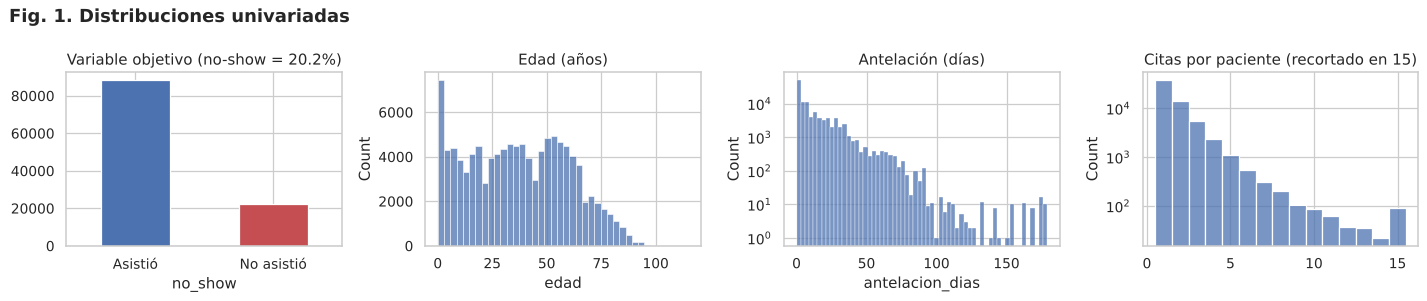

In [6]:
fig, ax = plt.subplots(1, 4, figsize=(16, 3.4))
d["no_show"].map({0: "Asistió", 1: "No asistió"}).value_counts().plot.bar(ax=ax[0], color=["#4C72B0", "#C44E52"])
ax[0].set_title(f"Variable objetivo (no-show = {y_rate:.1%})"); ax[0].tick_params(axis="x", rotation=0)
sns.histplot(d["edad"], bins=40, ax=ax[1], color="#4C72B0"); ax[1].set_title("Edad (años)")
sns.histplot(d["antelacion_dias"], bins=60, ax=ax[2], color="#4C72B0"); ax[2].set_title("Antelación (días)")
ax[2].set_yscale("log")
sns.histplot(cpp.clip(upper=15), discrete=True, ax=ax[3], color="#4C72B0")
ax[3].set_title("Citas por paciente (recortado en 15)"); ax[3].set_yscale("log")
fig.suptitle("Fig. 1. Distribuciones univariadas", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); fig.savefig(FIG / "fig1_univariado.png"); plt.show()

## 4. Análisis bivariado (variable vs. no-show)
Categóricas: χ² de independencia y V de Cramér corregida. Continuas: U de Mann-Whitney y r rank-biserial
(distribuciones asimétricas, se descarta t de Student). IC de Wilson al 95 % para las tasas.

In [7]:
rows = []
for c in bins + ["dia_semana", "grupo_edad", "antelacion_cat", "barrio"]:
    chi2, p, v = cramers_v(d[c], d["no_show"])
    rows.append((c, "χ²", chi2, p, "V de Cramér", v))
for c in ["edad", "antelacion_dias"]:
    u, p, r = mann_whitney_rb(d.loc[d.no_show == 1, c].values, d.loc[d.no_show == 0, c].values)
    rows.append((c, "U Mann-Whitney", u, p, "r rank-biserial", r))
biv = pd.DataFrame(rows, columns=["variable", "prueba", "estadistico", "p_valor", "efecto", "tamano_efecto"])
biv = biv.sort_values("tamano_efecto", key=np.abs, ascending=False)
biv.to_csv(TAB / "bivariado_pruebas.csv", index=False)
print(biv.round(4).to_string(index=False))
RESULTS["bivariado"] = biv.set_index("variable")["tamano_efecto"].round(3).to_dict()

              variable         prueba  estadistico  p_valor          efecto  tamano_efecto
       antelacion_dias U Mann-Whitney 1.374366e+09   0.0000 r rank-biserial         0.3965
        antelacion_cat             χ² 9.654529e+03   0.0000     V de Cramér         0.2955
             mismo_dia             χ² 8.879428e+03   0.0000     V de Cramér         0.2834
          sms_recibido             χ² 1.768653e+03   0.0000     V de Cramér         0.1265
                  edad U Mann-Whitney 8.974724e+08   0.0000 r rank-biserial        -0.0881
            grupo_edad             χ² 8.123113e+02   0.0000     V de Cramér         0.0854
                barrio             χ² 4.930138e+02   0.0000     V de Cramér         0.0611
          hipertension             χ² 1.405607e+02   0.0000     V de Cramér         0.0355
subsidio_bolsa_familia             χ² 9.401500e+01   0.0000     V de Cramér         0.0290
              diabetes             χ² 2.539250e+01   0.0000     V de Cramér         0.0149

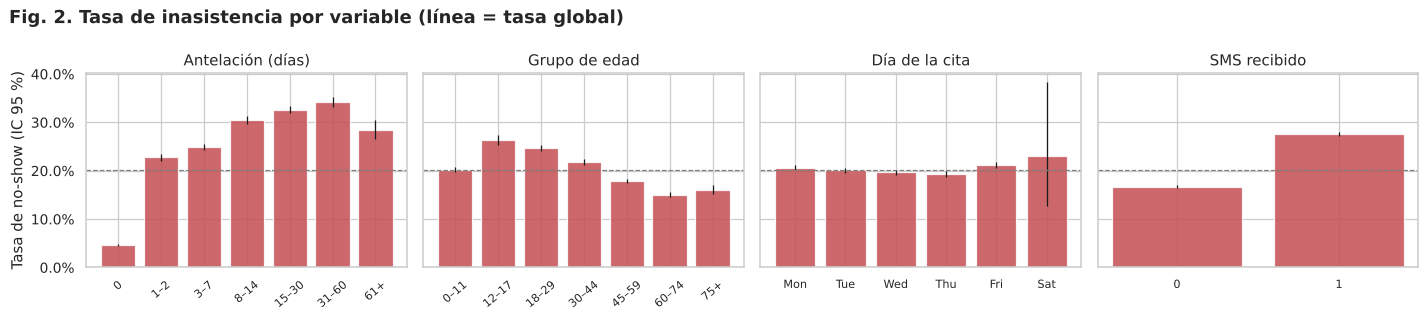

In [8]:
fig, ax = plt.subplots(1, 4, figsize=(16, 3.6), sharey=True)
for a, c, lab in zip(ax, ["antelacion_cat", "grupo_edad", "dia_semana", "sms_recibido"],
                     ["Antelación (días)", "Grupo de edad", "Día de la cita", "SMS recibido"]):
    t = rate_table(d, c)
    x = np.arange(len(t))
    a.bar(x, t["tasa"], color="#C44E52", alpha=.85)
    a.errorbar(x, t["tasa"], yerr=[t["tasa"] - t["ic95_inf"], t["ic95_sup"] - t["tasa"]], fmt="none", c="k", lw=1)
    a.set_xticks(x); a.set_xticklabels([str(i)[:3] if c == "dia_semana" else str(i) for i in t.index],
                                      rotation=40 if c in ("antelacion_cat", "grupo_edad") else 0, fontsize=9)
    a.axhline(y_rate, ls="--", c="grey", lw=1); a.set_title(lab); a.set_xlabel("")
ax[0].set_ylabel("Tasa de no-show (IC 95 %)"); ax[0].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
fig.suptitle("Fig. 2. Tasa de inasistencia por variable (línea = tasa global)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); fig.savefig(FIG / "fig2_bivariado.png"); plt.show()
RESULTS["tasa_por_antelacion"] = rate_table(d, "antelacion_cat")["tasa"].round(3).to_dict()
RESULTS["tasa_por_edad"] = rate_table(d, "grupo_edad")["tasa"].round(3).to_dict()
RESULTS["tasa_por_sms"] = rate_table(d, "sms_recibido")["tasa"].round(3).to_dict()

## 5. Análisis multivariado
### 5.1 Confusión: ¿el SMS "aumenta" la inasistencia? (paradoja de Simpson)
El SMS solo se envía a citas con cierta antelación, que a su vez es el principal predictor del no-show.
Se estratifica por antelación y se estima el OR ajustado de Mantel-Haenszel.

In [9]:
sms_by_lead = d.groupby("antelacion_cat", observed=True)["sms_recibido"].mean()
print("Proporción con SMS por antelación:\n", sms_by_lead.round(3).to_string())
ct = pd.crosstab(d["sms_recibido"], d["no_show"])
or_crudo = (ct.loc[1, 1] * ct.loc[0, 0]) / (ct.loc[1, 0] * ct.loc[0, 1])
d_sms = d[d["antelacion_dias"] >= 3]  # dominio donde el SMS es posible
or_mh, lo, hi = mantel_haenszel_or(d_sms, "sms_recibido", "no_show", "antelacion_dias")
print(f"OR crudo SMS = {or_crudo:.2f} | OR Mantel-Haenszel (estratos = días de antelación, ≥3 d) = {or_mh:.2f} [{lo:.2f}; {hi:.2f}]")
RESULTS["sms_or_crudo"] = round(float(or_crudo), 2)
RESULTS["sms_or_mh"] = [round(float(x), 2) for x in (or_mh, lo, hi)]
RESULTS["sms_min_antelacion"] = int(d.loc[d.sms_recibido == 1, "antelacion_dias"].min())

Proporción con SMS por antelación:
 antelacion_cat
0        0.000
1–2      0.000
3–7      0.570
8–14     0.582
15–30    0.606
31–60    0.611
61+      0.645
OR crudo SMS = 1.90 | OR Mantel-Haenszel (estratos = días de antelación, ≥3 d) = 0.77 [0.74; 0.80]


### 5.2 Modelo logístico exploratorio (efectos ajustados)
No es el modelo final: sirve para cuantificar asociaciones ajustadas mutuamente (OR con IC 95 %).

In [10]:
X = pd.DataFrame({
    "antelacion_10d": d["antelacion_dias"] / 10,
    "mismo_dia": d["mismo_dia"],
    "edad_10a": d["edad"] / 10,
    "sexo_F": (d["sexo"] == "F").astype(int),
    "subsidio": d["subsidio_bolsa_familia"],
    "hipertension": d["hipertension"], "diabetes": d["diabetes"],
    "alcoholismo": d["alcoholismo"], "discapacidad": d["discapacidad_bin"],
    "sms_recibido": d["sms_recibido"],
    "inasist_previas_ge1": (d["inasist_previas"] >= 1).astype(int),
    "sabado": (d["dia_semana"] == "Saturday").astype(int),
})
ors = logit_or_table(X, d["no_show"])
ors.to_csv(TAB / "logit_or_exploratorio.csv")
print(ors.round(3).to_string())
RESULTS["or_ajustados"] = ors[["OR", "ic95_inf", "ic95_sup", "p_valor"]].round(3).to_dict(orient="index")

                      beta     OR  ic95_inf  ic95_sup  p_valor
antelacion_10d       0.100  1.105     1.094     1.116    0.000
mismo_dia           -2.118  0.120     0.114     0.127    0.000
edad_10a            -0.101  0.904     0.897     0.912    0.000
sexo_F              -0.014  0.986     0.954     1.019    0.400
subsidio             0.264  1.302     1.238     1.370    0.000
hipertension        -0.076  0.926     0.881     0.974    0.003
diabetes             0.115  1.121     1.047     1.201    0.001
alcoholismo          0.330  1.391     1.268     1.527    0.000
discapacidad         0.097  1.102     0.982     1.238    0.100
sms_recibido        -0.178  0.837     0.810     0.866    0.000
inasist_previas_ge1  0.364  1.439     1.363     1.520    0.000
sabado               0.008  1.009     0.447     2.278    0.984


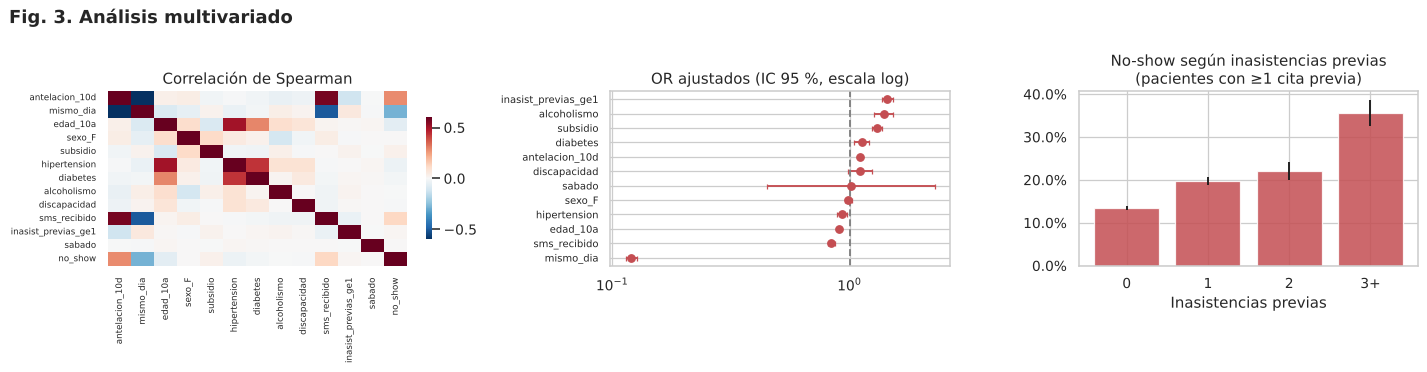

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2), gridspec_kw={"width_ratios": [1.1, 1, 1]})
corr = X.assign(no_show=d["no_show"]).corr(method="spearman")
sns.heatmap(corr, ax=ax[0], cmap="RdBu_r", center=0, vmin=-.6, vmax=.6, cbar_kws={"shrink": .7},
            xticklabels=True, yticklabels=True)
ax[0].set_title("Correlación de Spearman"); ax[0].tick_params(labelsize=7)
o = ors.sort_values("OR")
ax[1].errorbar(o["OR"], np.arange(len(o)), xerr=[o["OR"] - o["ic95_inf"], o["ic95_sup"] - o["OR"]],
               fmt="o", c="#C44E52", capsize=2)
ax[1].axvline(1, c="grey", ls="--"); ax[1].set_yticks(np.arange(len(o))); ax[1].set_yticklabels(o.index, fontsize=8)
ax[1].set_xscale("log"); ax[1].set_title("OR ajustados (IC 95 %, escala log)")
hist = d[d["citas_previas"] >= 1].copy()
hist["inasist_prev_cat"] = pd.cut(hist["inasist_previas"], [-1, 0, 1, 2, 100], labels=["0", "1", "2", "3+"])
t = rate_table(hist, "inasist_prev_cat")
ax[2].bar(t.index.astype(str), t["tasa"], color="#C44E52", alpha=.85)
ax[2].errorbar(np.arange(len(t)), t["tasa"], yerr=[t["tasa"] - t["ic95_inf"], t["ic95_sup"] - t["tasa"]], fmt="none", c="k")
ax[2].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax[2].set_title("No-show según inasistencias previas\n(pacientes con ≥1 cita previa)"); ax[2].set_xlabel("Inasistencias previas")
fig.suptitle("Fig. 3. Análisis multivariado", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); fig.savefig(FIG / "fig3_multivariado.png"); plt.show()
RESULTS["tasa_por_inasist_previas"] = t["tasa"].round(3).to_dict()
RESULTS["n_con_historial"] = int(len(hist))

### 5.3 Heterogeneidad territorial (funnel plot por barrio)
Se contrasta la tasa por barrio contra los límites binomiales del 95 % y 99,8 % alrededor de la tasa global,
para distinguir variación real de ruido por tamaño de muestra.

                      n  no_show   tasa  ic95_inf  ic95_sup
barrio                                                     
SANTA MARTHA       3131      496  0.158     0.146     0.172
JARDIM DA PENHA    3877      631  0.163     0.151     0.175
SANTO ANTÔNIO      2744      482  0.176     0.162     0.190
ANDORINHAS         2262      521  0.230     0.213     0.248
CARATOÍRA          2565      591  0.230     0.215     0.247
ILHA DO PRÍNCIPE   2266      532  0.235     0.218     0.253
JESUS DE NAZARETH  2853      696  0.244     0.229     0.260
ITARARÉ            3514      923  0.263     0.248     0.277
SANTA CLARA         506      134  0.265     0.228     0.305
SANTA CECÍLIA       448      123  0.275     0.235     0.318
SANTOS DUMONT      1276      369  0.289     0.265     0.315


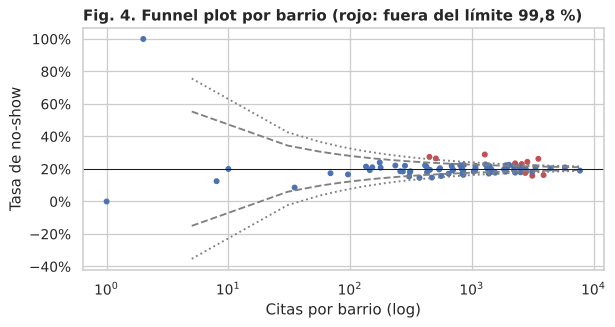

In [12]:
nb = rate_table(d, "barrio")
n_grid = np.linspace(max(5, nb["n"].min()), nb["n"].max(), 300)
fig, ax = plt.subplots(figsize=(7, 3.8))
for z, ls in [(1.96, "--"), (3.09, ":")]:
    se = np.sqrt(y_rate * (1 - y_rate) / n_grid)
    ax.plot(n_grid, y_rate + z * se, c="grey", ls=ls); ax.plot(n_grid, y_rate - z * se, c="grey", ls=ls)
out3 = (np.abs(nb["tasa"] - y_rate) > 3.09 * np.sqrt(y_rate * (1 - y_rate) / nb["n"]))
ax.scatter(nb["n"], nb["tasa"], s=14, c=np.where(out3, "#C44E52", "#4C72B0"))
ax.set_xscale("log"); ax.axhline(y_rate, c="k", lw=.8)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set_xlabel("Citas por barrio (log)"); ax.set_ylabel("Tasa de no-show")
ax.set_title("Fig. 4. Funnel plot por barrio (rojo: fuera del límite 99,8 %)", loc="left", fontweight="bold")
fig.tight_layout(); fig.savefig(FIG / "fig4_funnel_barrio.png"); plt.show()
RESULTS["barrios_fuera_998"] = int(out3.sum()); RESULTS["n_barrios"] = int(len(nb))
print(nb[out3].sort_values("tasa").round(3).to_string())

## 6. Suficiencia de los datos: línea base predictiva
Validación cruzada agrupada por paciente (GroupKFold, k = 5) para evitar que citas de un mismo paciente queden
en entrenamiento y prueba. Métricas: ROC-AUC, PR-AUC (referencia = prevalencia) y Brier.

In [13]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

feat_base = X.drop(columns=["inasist_previas_ge1"]).columns.tolist()
Xh = X.assign(citas_previas=d["citas_previas"], inasist_previas=d["inasist_previas"])
feat_hist = feat_base + ["citas_previas", "inasist_previas"]
y = d["no_show"].values; groups = d["paciente_id"].values
models = {
    "Regresión logística": lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "Gradient boosting (HGB)": lambda: HistGradientBoostingClassifier(random_state=SEED, max_iter=300, learning_rate=.08),
}
res = []
for fs_name, cols in [("Sin historial", feat_base), ("Con historial del paciente", feat_hist)]:
    for m_name, mk in models.items():
        sc = {"roc": [], "pr": [], "brier": [], "recall_top30": []}
        for tr, te in GroupKFold(n_splits=5).split(Xh, y, groups):
            m = mk().fit(Xh.iloc[tr][cols], y[tr]); p = m.predict_proba(Xh.iloc[te][cols])[:, 1]
            sc["roc"].append(roc_auc_score(y[te], p)); sc["pr"].append(average_precision_score(y[te], p))
            sc["brier"].append(brier_score_loss(y[te], p))
            top = p >= np.quantile(p, 0.70)  # contactar el 30 % de citas con mayor riesgo
            sc["recall_top30"].append(y[te][top].sum() / y[te].sum())
        res.append({"variables": fs_name, "modelo": m_name,
                    **{f"{k}_media": np.mean(v) for k, v in sc.items()}, **{f"{k}_de": np.std(v) for k, v in sc.items()}})
base = pd.DataFrame(res); base.to_csv(TAB / "linea_base_cv.csv", index=False)
print(base.round(4).to_string(index=False))
print(f"Referencia PR-AUC (clasificador aleatorio) = prevalencia = {y.mean():.3f}; Brier de predecir la prevalencia = {y.mean()*(1-y.mean()):.3f}")
RESULTS["linea_base"] = base.round(4).to_dict(orient="records")

                 variables                  modelo  roc_media  pr_media  brier_media  recall_top30_media  roc_de  pr_de  brier_de  recall_top30_de
             Sin historial     Regresión logística     0.7155    0.3376       0.1459              0.4997  0.0029 0.0059    0.0011           0.0045
             Sin historial Gradient boosting (HGB)     0.7273    0.3568       0.1445              0.5243  0.0029 0.0066    0.0010           0.0048
Con historial del paciente     Regresión logística     0.7203    0.3427       0.1452              0.5039  0.0030 0.0029    0.0011           0.0046
Con historial del paciente Gradient boosting (HGB)     0.7326    0.3639       0.1436              0.5294  0.0035 0.0050    0.0012           0.0058
Referencia PR-AUC (clasificador aleatorio) = prevalencia = 0.202; Brier de predecir la prevalencia = 0.161


## 7. Hallazgos y guardado de resultados
Ver interpretación en el reporte ejecutivo (`reports/Entrega1_Reporte.pdf`).

In [14]:
with open(TAB / "resultados_eda.json", "w", encoding="utf-8") as f:
    json.dump(RESULTS, f, ensure_ascii=False, indent=1, default=str)
print(json.dumps(RESULTS, ensure_ascii=False, indent=1, default=str)[:3000])

{
 "n_citas": 110527,
 "n_pacientes": 62299,
 "periodo_citas": [
  "2016-04-29",
  "2016-06-08"
 ],
 "periodo_agendamiento": [
  "2015-11-10",
  "2016-06-08"
 ],
 "calidad": {
  "Valores nulos (todas las columnas)": 0,
  "cita_id duplicado": 0,
  "Filas duplicadas sin cita_id": 618,
  "edad < 0": 1,
  "edad > 100": 7,
  "discapacidad fuera de {0,1} (codificada 0–4)": 199,
  "fecha_cita anterior a fecha_agendamiento": 5,
  "fecha_cita sin hora (todas 00:00)": 110527,
  "paciente_id no entero (float corrupto)": 5,
  "sexo: categorías": "F, M",
  "barrio: cardinalidad": 81,
  "días de la semana con citas": 6
 },
 "registros_excluidos": 6,
 "pct_con_historial": 0.279,
 "tasa_no_show": 0.2019,
 "citas_por_paciente": {
  "media": 1.77,
  "p50": 1,
  "p99": 8,
  "max": 88,
  "pct_pacientes_1_cita": 0.609
 },
 "antelacion": {
  "mediana": 4.0,
  "pct_mismo_dia": 0.349,
  "asimetria": 2.67
 },
 "pct_sms": 0.321,
 "bivariado": {
  "antelacion_dias": 0.397,
  "antelacion_cat": 0.295,
  "mismo_dia